# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 7: Acciones preventivas — ANN

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** ANN — Recomendaciones de control vectorial  
**Dataset:** `vectoria_acciones.csv`  
**Fuente:** Material entregado por el profesor (datos de casos y clima derivados de OPS/PAHO y NASA POWER; predicción, detección y etiquetas simuladas).  
**Período descrito:** 2017–2024, con cinco escenarios por semana.

---

### Objetivo del análisis

Explorar la calidad, organización y distribución del dataset, evaluar el desbalance de recomendaciones, las relaciones entre variables climáticas, casos estimados y umbral endémico, y revisar las reglas que generan la etiqueta objetivo. Identificar riesgos de fuga de información para orientar el entrenamiento posterior de la ANN.


## 1. Importación de librerías

Se importan una sola vez las herramientas para explorar tablas y visualizar resultados. No se necesitan librerías de aprendizaje profundo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

## 2. Carga y exploración inicial del dataset

Se carga el CSV original sin modificarlo, usando la ubicación del proyecto VectorIA proporcionada.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\VectorIA-datos")
archivo = ruta / "vectoria_acciones.csv"

datos = pd.read_csv(archivo, parse_dates=["fecha_inicio_semana"])
datos = datos.sort_values(["fecha_inicio_semana", "escenario"]).reset_index(drop=True)

print("Archivo:", archivo.name)
display(datos.head(10))

Archivo: vectoria_acciones.csv


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
5,2017-01-08,2017,2,1,302,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
6,2017-01-08,2017,2,2,331,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
7,2017-01-08,2017,2,3,315,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
8,2017-01-08,2017,2,4,339,1720,59.2,26.3,20.2,84.4,1,monitoreo_normal
9,2017-01-08,2017,2,5,348,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal


## 3. Dimensiones del dataset

Se identifica el número de filas y columnas para determinar el tamaño del conjunto de datos.

In [3]:
filas, columnas = datos.shape
print(f"Filas: {filas:,}")
print(f"Columnas: {columnas}")
print("Variables:", ", ".join(datos.columns))

Filas: 2,060
Columnas: 12
Variables: fecha_inicio_semana, anio, semana_epi, escenario, casos_pred_4sem, casos_umbral_endemico, lluvia_14d_mm, temp_max, temp_min, humedad, aegypti_detectado, recomendacion


## 4. Identificación de variables y tipos de datos

Se distinguen las variables numéricas, temporales y categóricas. La variable objetivo para la ANN es `recomendacion`.

In [4]:
display(datos.dtypes.rename("Tipo de dato").to_frame())
print("Información general:")
datos.info()

,Tipo de dato
fecha_inicio_semana,datetime64[us]
anio,int64
semana_epi,int64
escenario,int64
casos_pred_4sem,int64
casos_umbral_endemico,int64
lluvia_14d_mm,float64
temp_max,float64
temp_min,float64
humedad,float64


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   fecha_inicio_semana    2060 non-null   datetime64[us]
 1   anio                   2060 non-null   int64         
 2   semana_epi             2060 non-null   int64         
 3   escenario              2060 non-null   int64         
 4   casos_pred_4sem        2060 non-null   int64         
 5   casos_umbral_endemico  2060 non-null   int64         
 6   lluvia_14d_mm          2060 non-null   float64       
 7   temp_max               2060 non-null   float64       
 8   temp_min               2060 non-null   float64       
 9   humedad                2060 non-null   float64       
 10  aegypti_detectado      2060 non-null   int64         
 11  recomendacion          2060 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(6), str(1)
m

## 5. Estadísticas descriptivas

Se analizan valores mínimos, máximos, medidas centrales y dispersión de las variables numéricas y la frecuencia de las categorías.

In [5]:
display(datos.describe(include=["number"]).T.round(2))
print("Resumen de recomendaciones:")
display(datos["recomendacion"].describe().to_frame("Valor"))

,count,mean,std,min,25%,50%,75%,max
anio,2060.0,2020.47,2.28,2017.0,2018.00,2020.0,2022.00,2024.0
semana_epi,2060.0,26.27,14.90,1.0,13.00,26.0,39.00,52.0
escenario,2060.0,3.00,1.41,1.0,2.00,3.0,4.00,5.0
casos_pred_4sem,2060.0,1006.49,1334.23,75.0,244.00,490.0,1086.00,10021.0
casos_umbral_endemico,2060.0,999.67,603.59,210.0,464.75,871.0,1411.00,2612.0
lluvia_14d_mm,2060.0,113.23,106.76,0.3,32.12,95.2,163.35,867.6
temp_max,2060.0,27.77,1.66,24.4,26.60,27.3,28.70,32.7
temp_min,2060.0,21.11,0.93,18.4,20.50,21.2,21.80,23.2
humedad,2060.0,84.14,7.37,64.3,80.22,87.0,89.50,94.9
aegypti_detectado,2060.0,0.42,0.49,0.0,0.00,0.0,1.00,1.0


Resumen de recomendaciones:


,Valor
count,2060
unique,4
top,monitoreo_normal
freq,1213


## 6. Análisis de valores faltantes

Se revisa la cantidad y proporción de registros nulos por variable.

In [6]:
faltantes = datos.isna().sum()
tabla_faltantes = pd.DataFrame({
    "Variable": faltantes.index,
    "Valores faltantes": faltantes.values,
    "Porcentaje (%)": (100 * faltantes.values / len(datos)).round(2)
})
display(tabla_faltantes)
print("Total de celdas vacías:", int(faltantes.sum()))

,Variable,Valores faltantes,Porcentaje (%)
0,fecha_inicio_semana,0,0.0
1,anio,0,0.0
2,semana_epi,0,0.0
3,escenario,0,0.0
4,casos_pred_4sem,0,0.0
5,casos_umbral_endemico,0,0.0
6,lluvia_14d_mm,0,0.0
7,temp_max,0,0.0
8,temp_min,0,0.0
9,humedad,0,0.0


Total de celdas vacías: 0


## 7. Detección de registros duplicados

Se revisan filas exactamente repetidas y claves duplicadas de **semana + escenario**. Es normal que una semana aparezca cinco veces, porque representa cinco escenarios distintos.

In [7]:
duplicados_exactos = int(datos.duplicated().sum())
duplicados_clave = int(datos.duplicated(subset=["fecha_inicio_semana", "escenario"]).sum())
filas_por_semana = datos.groupby("fecha_inicio_semana").size()

print("Filas completamente duplicadas:", duplicados_exactos)
print("Duplicados de fecha + escenario:", duplicados_clave)
print("Número de semanas distintas:", filas_por_semana.size)
print("Distribución de escenarios por semana:")
display(filas_por_semana.value_counts().sort_index().rename_axis("Registros por semana").to_frame("Número de semanas"))

Filas completamente duplicadas: 0
Duplicados de fecha + escenario: 0
Número de semanas distintas: 412
Distribución de escenarios por semana:


,Número de semanas
Registros por semana,
5,412


## 8. Valores únicos y variables categóricas

Se identifican las categorías presentes y la cantidad de valores distintos de cada columna.

In [8]:
display(datos.nunique(dropna=False).sort_values().rename("Valores distintos").to_frame())
for columna in ["escenario", "aegypti_detectado", "recomendacion"]:
    print(f"\n{columna}:")
    display(datos[columna].value_counts(dropna=False).sort_index().rename("Cantidad").to_frame())

,Valores distintos
aegypti_detectado,2
recomendacion,4
escenario,5
anio,8
temp_min,48
semana_epi,52
temp_max,77
humedad,192
casos_umbral_endemico,287
lluvia_14d_mm,372



escenario:


,Cantidad
escenario,
1,412
2,412
3,412
4,412
5,412



aegypti_detectado:


,Cantidad
aegypti_detectado,
0,1203
1,857



recomendacion:


,Cantidad
recomendacion,
alerta_sanitaria,379
eliminacion_criaderos,321
fumigacion_focalizada,147
monitoreo_normal,1213


## 9. Distribución de variables numéricas

Los histogramas permiten identificar concentración, asimetría y dispersión de casos y clima. Los valores extremos no se eliminan durante el EDA.

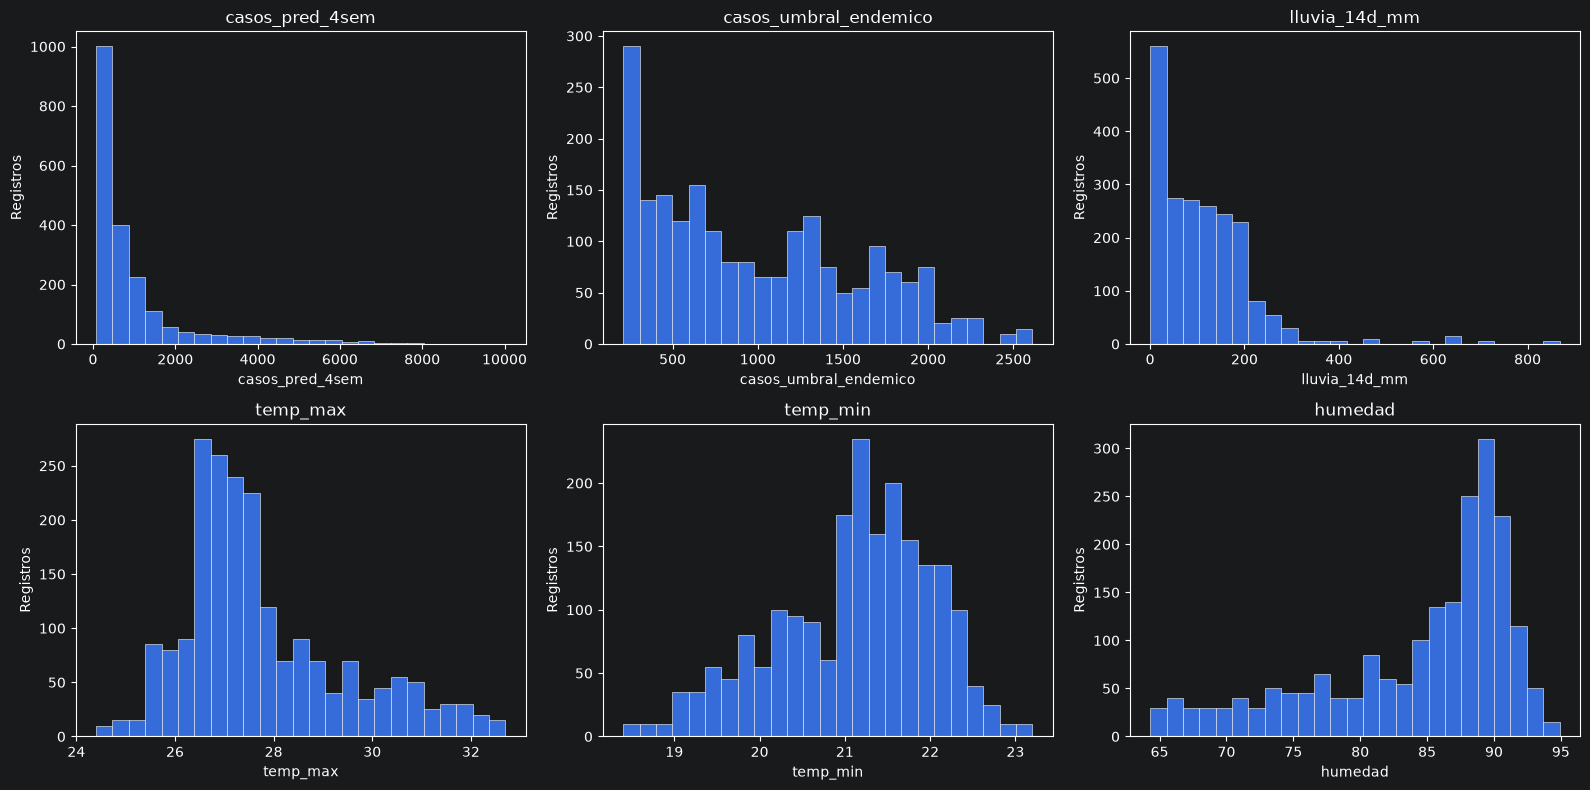

In [9]:
variables_numericas = [
    "casos_pred_4sem", "casos_umbral_endemico", "lluvia_14d_mm",
    "temp_max", "temp_min", "humedad"
]
fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for eje, variable in zip(ejes.flat, variables_numericas):
    eje.hist(datos[variable].dropna(), bins=25, edgecolor="white", linewidth=0.4)
    eje.set_title(variable)
    eje.set_xlabel(variable)
    eje.set_ylabel("Registros")
plt.tight_layout()
plt.show()

## 10. Detección de valores atípicos (IQR)

Se resumen los registros fuera de los rangos intercuartílicos. Estas observaciones pueden corresponder a epidemias o eventos climáticos reales; no deben eliminarse automáticamente.

In [10]:
filas_outliers = []
for variable in variables_numericas:
    serie = datos[variable].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((serie < li) | (serie > ls)).sum())
    filas_outliers.append({"Variable": variable, "Límite inferior": li, "Límite superior": ls,
                           "Valores atípicos": n, "Porcentaje (%)": round(100*n / len(serie), 2)})
tabla_outliers = pd.DataFrame(filas_outliers)
display(tabla_outliers.round(2))

,Variable,Límite inferior,Límite superior,Valores atípicos,Porcentaje (%)
0,casos_pred_4sem,-1019.00,2349.00,236,11.46
1,casos_umbral_endemico,-954.62,2830.38,0,0.00
2,lluvia_14d_mm,-164.71,360.19,50,2.43
3,temp_max,23.45,31.85,50,2.43
4,temp_min,18.55,23.75,10,0.49
5,humedad,66.31,103.41,50,2.43


## 11. Validación de rangos y consistencia

Se comprueban rangos físicamente posibles, coherencia de temperaturas, codificación binaria, escenarios y categorías válidas. Son controles básicos de calidad, no correcciones automáticas.

In [11]:
clases_validas = {
    "alerta_sanitaria", "fumigacion_focalizada",
    "eliminacion_criaderos", "monitoreo_normal"
}
controles = {
    "Pronóstico de casos negativo": (datos["casos_pred_4sem"] < 0).sum(),
    "Umbral endémico negativo": (datos["casos_umbral_endemico"] < 0).sum(),
    "Lluvia negativa": (datos["lluvia_14d_mm"] < 0).sum(),
    "Temperatura mínima superior a la máxima": (datos["temp_min"] > datos["temp_max"]).sum(),
    "Humedad fuera de 0–100 %": (~datos["humedad"].between(0, 100)).sum(),
    "Aedes detectado fuera de {0, 1}": (~datos["aegypti_detectado"].isin([0, 1])).sum(),
    "Escenario fuera de 1–5": (~datos["escenario"].isin(range(1, 6))).sum(),
    "Recomendación desconocida": (~datos["recomendacion"].isin(clases_validas)).sum(),
    "Año no coincide con fecha": (datos["anio"] != datos["fecha_inicio_semana"].dt.year).sum(),
    "Semana epidemiológica fuera de 1–53": (~datos["semana_epi"].between(1, 53)).sum()
}
tabla_controles = pd.DataFrame(controles.items(), columns=["Comprobación", "Registros observados"])
display(tabla_controles)
print("Total de observaciones de controles:", int(sum(controles.values())))

,Comprobación,Registros observados
0,Pronóstico de casos negativo,0
1,Umbral endémico negativo,0
2,Lluvia negativa,0
3,Temperatura mínima superior a la máxima,0
4,Humedad fuera de 0–100 %,0
5,"Aedes detectado fuera de {0, 1}",0
6,Escenario fuera de 1–5,0
7,Recomendación desconocida,0
8,Año no coincide con fecha,20
9,Semana epidemiológica fuera de 1–53,0


Total de observaciones de controles: 20


## 12. Visualizaciones comparativas iniciales

Se utilizan diagramas de caja independientes para comparar la dispersión de variables con unidades diferentes.

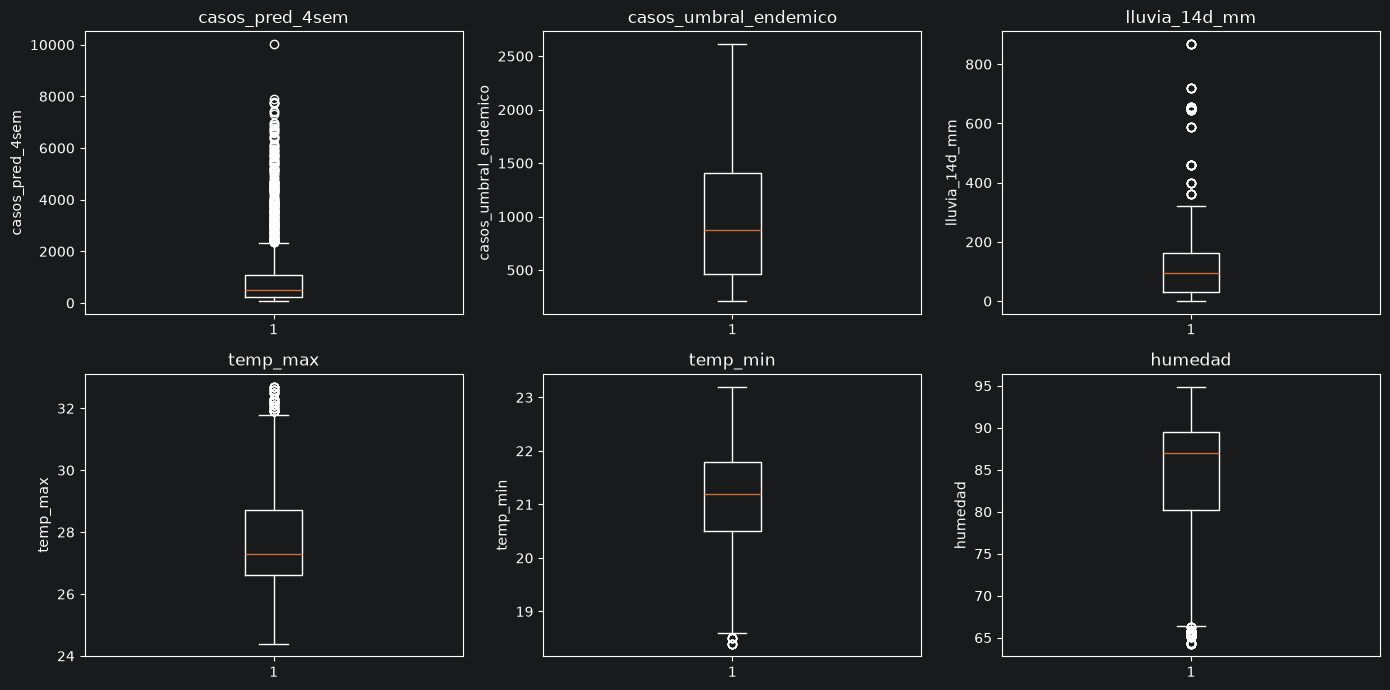

In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, variable in zip(ejes.flat, variables_numericas):
    eje.boxplot(datos[variable].dropna())
    eje.set_title(variable)
    eje.set_ylabel(variable)
plt.tight_layout()
plt.show()

## 13. Cobertura temporal y semanas epidemiológicas

Se verifica la cobertura entre 2017 y 2024, la fecha de inicio semanal, el número de semanas registradas y la continuidad. El archivo de 2024 puede abarcar solo una parte del año.

In [13]:
semanas = datos[["fecha_inicio_semana", "anio", "semana_epi"]].drop_duplicates().sort_values("fecha_inicio_semana")
fechas_esperadas = pd.date_range(semanas["fecha_inicio_semana"].min(), semanas["fecha_inicio_semana"].max(), freq="W-SUN")
fechas_faltantes = fechas_esperadas.difference(pd.DatetimeIndex(semanas["fecha_inicio_semana"]))

print("Primera semana:", semanas["fecha_inicio_semana"].min().date())
print("Última semana:", semanas["fecha_inicio_semana"].max().date())
print("Semanas únicas:", len(semanas))
print("Semanas ausentes dentro del período:", len(fechas_faltantes))
print("Fechas que NO comienzan en domingo:", int((semanas["fecha_inicio_semana"].dt.dayofweek != 6).sum()))
print("Semanas por año:")
display(semanas.groupby("anio").size().rename("Semanas registradas").to_frame())

Primera semana: 2017-01-01
Última semana: 2024-11-24
Semanas únicas: 412
Semanas ausentes dentro del período: 1
Fechas que NO comienzan en domingo: 0
Semanas por año:


C:\Users\andre\AppData\Local\Temp\ipykernel_25176\2040729934.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  print("Fechas que NO comienzan en domingo:", int((semanas["fecha_inicio_semana"].dt.dayofweek != 6).sum()))


,Semanas registradas
anio,
2017,52
2018,52
2019,52
2020,52
2021,52
2022,52
2023,52
2024,48


## 14. Distribución de recomendaciones preventivas

Se cuentan las cuatro clases objetivo y sus porcentajes. En este dataset la clase es una recomendación generada mediante reglas, no un diagnóstico clínico.

,Recomendación,Cantidad,Porcentaje (%)
0,monitoreo_normal,1213,58.88
1,alerta_sanitaria,379,18.40
2,eliminacion_criaderos,321,15.58
3,fumigacion_focalizada,147,7.14


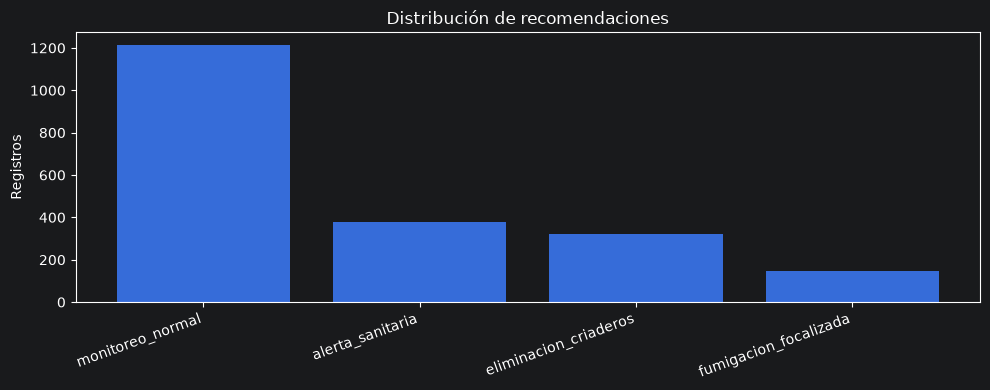

In [14]:
tabla_recomendaciones = datos["recomendacion"].value_counts().rename_axis("Recomendación").reset_index(name="Cantidad")
tabla_recomendaciones["Porcentaje (%)"] = (100 * tabla_recomendaciones["Cantidad"] / len(datos)).round(2)
display(tabla_recomendaciones)

plt.figure(figsize=(10, 4))
plt.bar(tabla_recomendaciones["Recomendación"], tabla_recomendaciones["Cantidad"])
plt.ylabel("Registros")
plt.title("Distribución de recomendaciones")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 15. Análisis del desbalance de clases

Se compara la clase con más registros frente a la menos frecuente y se describe la proporción de muestras de cada etiqueta.

In [15]:
mayoritaria = tabla_recomendaciones.iloc[0]
minoritaria = tabla_recomendaciones.iloc[-1]
relacion_desbalance = mayoritaria["Cantidad"] / minoritaria["Cantidad"]
print(f"Mayoritaria: {mayoritaria['Recomendación']} ({mayoritaria['Cantidad']} registros)")
print(f"Minoritaria: {minoritaria['Recomendación']} ({minoritaria['Cantidad']} registros)")
print(f"Relación de desbalance: {relacion_desbalance:.2f}:1")

display(tabla_recomendaciones)

Mayoritaria: monitoreo_normal (1213 registros)
Minoritaria: fumigacion_focalizada (147 registros)
Relación de desbalance: 8.25:1


,Recomendación,Cantidad,Porcentaje (%)
0,monitoreo_normal,1213,58.88
1,alerta_sanitaria,379,18.40
2,eliminacion_criaderos,321,15.58
3,fumigacion_focalizada,147,7.14


## 16. Distribución de los cinco escenarios por semana

Cada semana debe presentar cinco escenarios. Se comprueba su cobertura y el número de recomendaciones diferentes que puede producir una misma semana.

In [16]:
matriz_escenarios = pd.crosstab(datos["fecha_inicio_semana"], datos["escenario"])
escenarios_completos = (matriz_escenarios.eq(1).all(axis=1)).sum()
variabilidad_etiquetas = datos.groupby("fecha_inicio_semana")["recomendacion"].nunique()

print(f"Semanas con exactamente un registro de cada escenario (1–5): {escenarios_completos} de {len(matriz_escenarios)}")
print("Número de recomendaciones distintas por semana:")
display(variabilidad_etiquetas.value_counts().sort_index().rename_axis("Recomendaciones diferentes").to_frame("Semanas"))
print("Escenarios presentes:")
display(datos["escenario"].value_counts().sort_index().rename("Cantidad").to_frame())

Semanas con exactamente un registro de cada escenario (1–5): 412 de 412
Número de recomendaciones distintas por semana:


,Semanas
Recomendaciones diferentes,
1,276
2,109
3,27


Escenarios presentes:


,Cantidad
escenario,
1,412
2,412
3,412
4,412
5,412


## 17. Origen y naturaleza de las variables

Según el archivo `LEEME_datos.md` del profesor, el dataset mezcla **datos reales, atributos derivados y simulaciones**. Es importante distinguirlos antes de conectar la ANN con los modelos CNN y LSTM.

- **Reales o derivados de datos reales:** lluvia, temperaturas, humedad, fechas y umbral endémico simplificado.
- **Simulados:** `casos_pred_4sem` (como si fuera una predicción de LSTM) y `aegypti_detectado` (como si fuera salida de la CNN).
- **Generadas mediante reglas con ruido:** etiquetas `recomendacion`.

Este EDA no cambia el origen de los valores ni trata las predicciones simuladas como pronósticos operativos.

In [17]:
origen_variables = pd.DataFrame([
    ("fecha_inicio_semana, anio, semana_epi", "Temporal", "Referencias temporales"),
    ("escenario", "Simulado", "Identificador de las cinco variantes por semana"),
    ("casos_pred_4sem", "Simulado", "Pronóstico artificial de cuatro semanas"),
    ("casos_umbral_endemico", "Derivado", "Umbral calculado a partir del historial real"),
    ("lluvia_14d_mm, temp_max, temp_min, humedad", "Real / agregado", "Datos climáticos provenientes de la serie nacional"),
    ("aegypti_detectado", "Simulado", "Detección artificial de Aedes"),
    ("recomendacion", "Etiqueta por reglas", "Acción preventiva con ruido añadido")
], columns=["Variable(s)", "Origen / tipo", "Función"])
display(origen_variables)

,Variable(s),Origen / tipo,Función
0,"fecha_inicio_semana, anio, semana_epi",Temporal,Referencias temporales
1,escenario,Simulado,Identificador de las cinco variantes por semana
2,casos_pred_4sem,Simulado,Pronóstico artificial de cuatro semanas
3,casos_umbral_endemico,Derivado,Umbral calculado a partir del historial real
4,"lluvia_14d_mm, temp_max, temp_min, humedad",Real / agregado,Datos climáticos provenientes de la serie naci...
5,aegypti_detectado,Simulado,Detección artificial de Aedes
6,recomendacion,Etiqueta por reglas,Acción preventiva con ruido añadido


## 18. Relación entre casos pronosticados y umbral endémico

Se calcula cuántas veces el pronóstico supera el umbral, variable importante para las reglas de recomendación. Se utiliza una razón segura ante posibles umbrales iguales a cero.

Resumen de la razón pronóstico / umbral:


,Razón
count,2060.00
mean,1.42
std,2.26
min,0.04
25%,0.31
50%,0.65
75%,1.42
max,21.88


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal,All
razon_pred_umbral,,,,,
Pronóstico ≤ umbral,10,265,8,1064,1347
Umbral < pronóstico ≤ 2×,4,54,138,147,343
Pronóstico > 2×,365,2,1,2,370
All,379,321,147,1213,2060


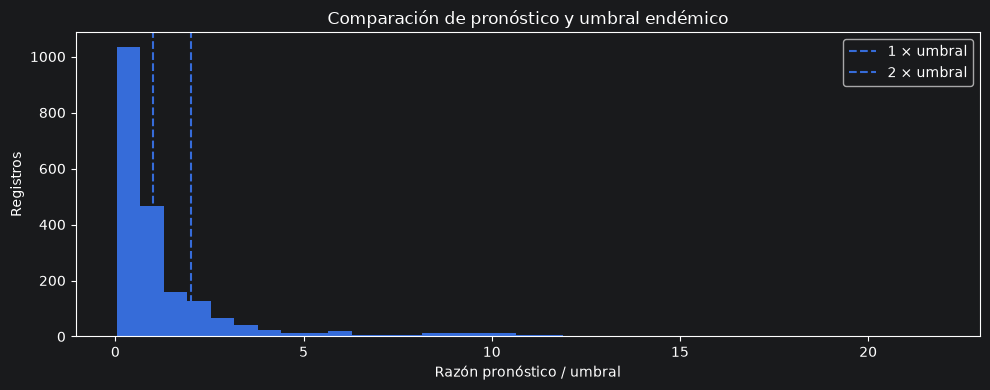

In [18]:
datos["razon_pred_umbral"] = np.where(
    datos["casos_umbral_endemico"] > 0,
    datos["casos_pred_4sem"] / datos["casos_umbral_endemico"].replace(0, np.nan),
    np.nan
)
print("Resumen de la razón pronóstico / umbral:")
display(datos["razon_pred_umbral"].describe().to_frame("Razón").round(2))

rangos = pd.cut(datos["razon_pred_umbral"], [-np.inf, 1, 2, np.inf],
                labels=["Pronóstico ≤ umbral", "Umbral < pronóstico ≤ 2×", "Pronóstico > 2×"])
display(pd.crosstab(rangos, datos["recomendacion"], margins=True))
plt.figure(figsize=(10, 4))
plt.hist(datos["razon_pred_umbral"].dropna(), bins=35)
plt.axvline(1, linestyle="--", label="1 × umbral")
plt.axvline(2, linestyle="--", label="2 × umbral")
plt.xlabel("Razón pronóstico / umbral")
plt.ylabel("Registros")
plt.title("Comparación de pronóstico y umbral endémico")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Visualización del pronóstico frente al umbral

Se comparan gráficamente ambas variables y se marcan los límites de una y dos veces el umbral. Estas líneas ayudan a interpretar las reglas, pero no sustituyen su validación completa.

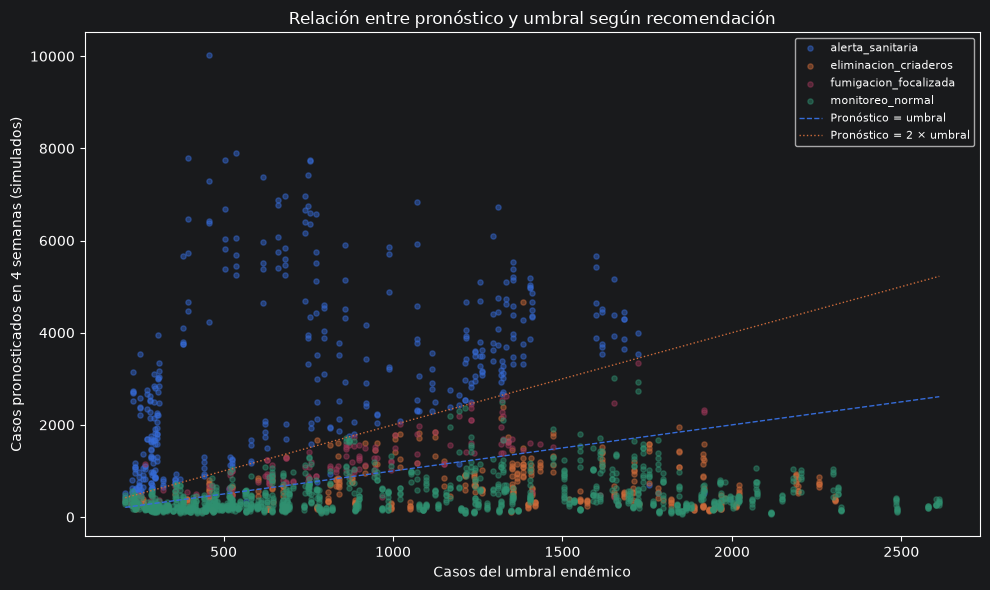

In [19]:
plt.figure(figsize=(10, 6))
for clase, grupo in datos.groupby("recomendacion"):
    plt.scatter(grupo["casos_umbral_endemico"], grupo["casos_pred_4sem"],
                label=clase, s=14, alpha=0.45)
xlim = np.linspace(datos["casos_umbral_endemico"].min(), datos["casos_umbral_endemico"].max(), 200)
plt.plot(xlim, xlim, linestyle="--", linewidth=1, label="Pronóstico = umbral")
plt.plot(xlim, 2*xlim, linestyle=":", linewidth=1, label="Pronóstico = 2 × umbral")
plt.xlabel("Casos del umbral endémico")
plt.ylabel("Casos pronosticados en 4 semanas (simulados)")
plt.title("Relación entre pronóstico y umbral según recomendación")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 20. Análisis de lluvia acumulada en 14 días

Se estudia la lluvia y la frecuencia de registros por encima de 80 mm, condición que interviene en la regla de eliminación de criaderos junto con temperatura máxima superior a 27 °C.

Registros con lluvia > 80 mm: 1170
Porcentaje: 56.80 %


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal,All
Lluvia > 80 mm,,,,,
False,157,7,32,694,890
True,222,314,115,519,1170
All,379,321,147,1213,2060


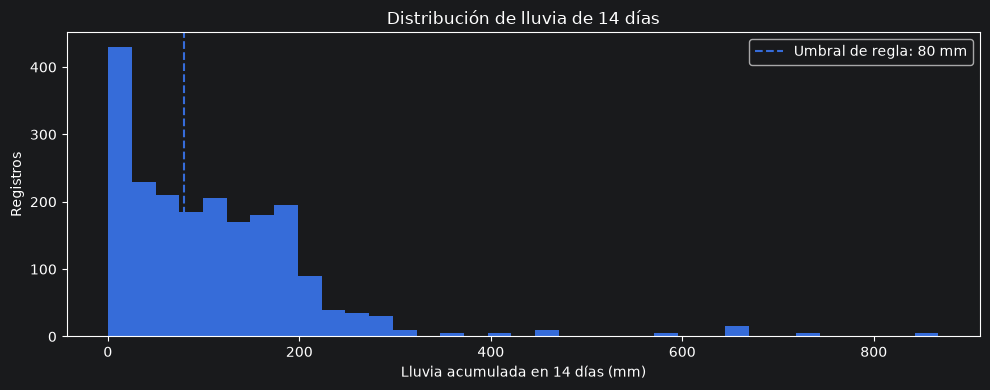

In [20]:
lluvia_alta = datos["lluvia_14d_mm"] > 80
print("Registros con lluvia > 80 mm:", int(lluvia_alta.sum()))
print(f"Porcentaje: {lluvia_alta.mean()*100:.2f} %")
display(pd.crosstab(lluvia_alta.rename("Lluvia > 80 mm"), datos["recomendacion"], margins=True))
plt.figure(figsize=(10, 4))
plt.hist(datos["lluvia_14d_mm"], bins=35)
plt.axvline(80, linestyle="--", label="Umbral de regla: 80 mm")
plt.xlabel("Lluvia acumulada en 14 días (mm)")
plt.ylabel("Registros")
plt.title("Distribución de lluvia de 14 días")
plt.legend()
plt.tight_layout()
plt.show()

## 21. Análisis de temperatura y humedad

Se observan las distribuciones de temperatura máxima y mínima y humedad relativa. Se marca la condición de temperatura máxima mayor que 27 °C usada en una regla.

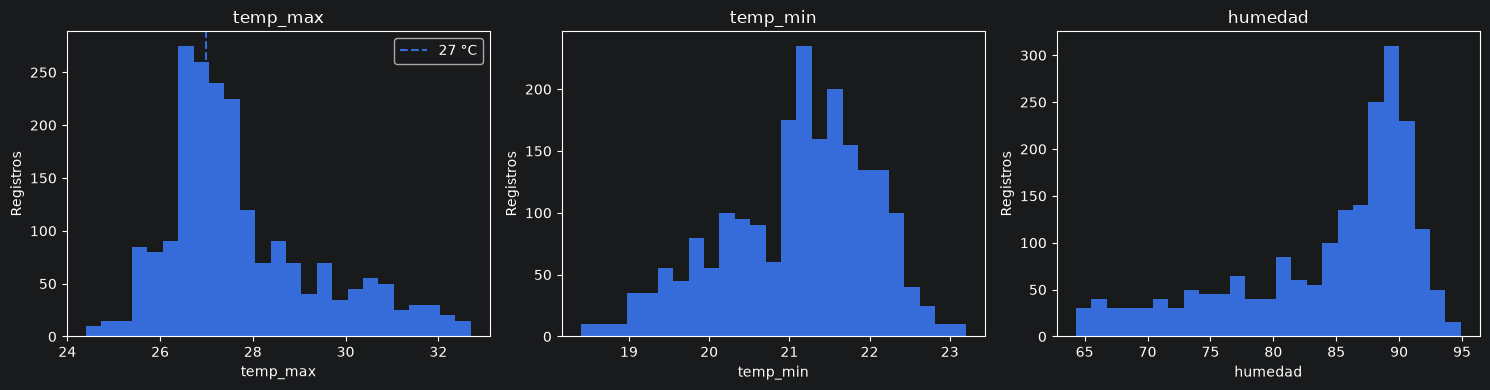

Registros que cumplen lluvia > 80 mm y temp_max > 27 °C: 505
Nota: las reglas de mayor prioridad pueden asignar otra recomendación a estos registros.


In [21]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, variable in zip(ejes, ["temp_max", "temp_min", "humedad"]):
    eje.hist(datos[variable], bins=25)
    eje.set_title(variable)
    eje.set_xlabel(variable)
    eje.set_ylabel("Registros")
ejes[0].axvline(27, linestyle="--", label="27 °C")
ejes[0].legend()
plt.tight_layout()
plt.show()

ambas_condiciones = (datos["lluvia_14d_mm"] > 80) & (datos["temp_max"] > 27)
print("Registros que cumplen lluvia > 80 mm y temp_max > 27 °C:", int(ambas_condiciones.sum()))
print("Nota: las reglas de mayor prioridad pueden asignar otra recomendación a estos registros.")

## 22. Distribución de `aegypti_detectado`

Se compara la frecuencia de los valores 0 (no detectado) y 1 (detectado) con las recomendaciones. Este indicador está **simulado** en el dataset del profesor.

recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal,All
aegypti_detectado,,,,,
0,213,185,4,801,1203
1,166,136,143,412,857
All,379,321,147,1213,2060


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
aegypti_detectado,,,,
0,17.7,15.4,0.3,66.6
1,19.4,15.9,16.7,48.1


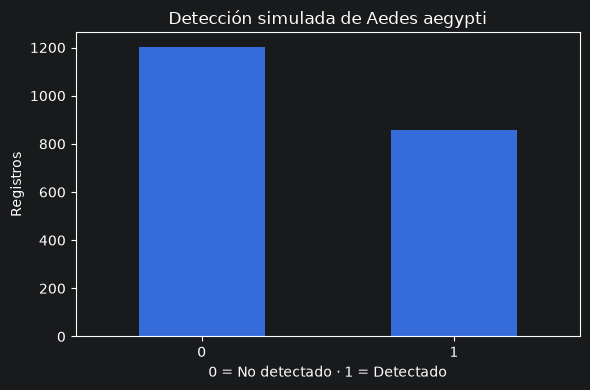

In [22]:
tabla_aedes = pd.crosstab(datos["aegypti_detectado"], datos["recomendacion"], margins=True)
display(tabla_aedes)
display(pd.crosstab(datos["aegypti_detectado"], datos["recomendacion"], normalize="index").mul(100).round(1))

datos["aegypti_detectado"].value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plt.title("Detección simulada de Aedes aegypti")
plt.xlabel("0 = No detectado · 1 = Detectado")
plt.ylabel("Registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 23. Matriz de correlaciones entre variables predictoras

Se calcula la correlación de Pearson entre variables numéricas. Es una asociación descriptiva, no prueba causalidad. `recomendacion` no tiene una interpretación numérica directa para este análisis.

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado
casos_pred_4sem,1.00,0.01,0.22,-0.05,0.45,0.27,0.12
casos_umbral_endemico,0.01,1.00,0.40,-0.53,0.29,0.62,0.25
lluvia_14d_mm,0.22,0.40,1.00,-0.47,0.41,0.60,0.35
temp_max,-0.05,-0.53,-0.47,1.00,0.06,-0.87,-0.21
temp_min,0.45,0.29,0.41,0.06,1.00,0.37,0.26
humedad,0.27,0.62,0.60,-0.87,0.37,1.00,0.30
aegypti_detectado,0.12,0.25,0.35,-0.21,0.26,0.30,1.00


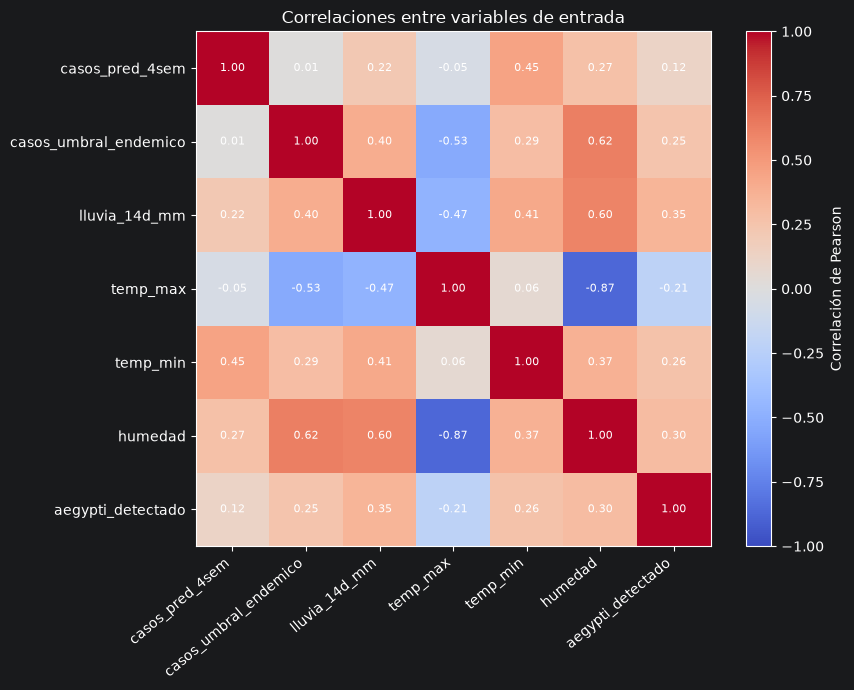

In [23]:
columnas_corr = ["casos_pred_4sem", "casos_umbral_endemico", "lluvia_14d_mm",
                 "temp_max", "temp_min", "humedad", "aegypti_detectado"]
matriz_corr = datos[columnas_corr].corr()
display(matriz_corr.round(2))
fig, eje = plt.subplots(figsize=(9, 7))
im = eje.imshow(matriz_corr, vmin=-1, vmax=1, cmap="coolwarm")
eje.set_xticks(range(len(columnas_corr)), columnas_corr, rotation=40, ha="right")
eje.set_yticks(range(len(columnas_corr)), columnas_corr)
for i in range(len(columnas_corr)):
    for j in range(len(columnas_corr)):
        eje.text(j, i, f"{matriz_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=eje, label="Correlación de Pearson")
eje.set_title("Correlaciones entre variables de entrada")
plt.tight_layout()
plt.show()

## 24. Comparación de variables por recomendación

Se resumen medianas y se comparan las distribuciones de casos, umbral y clima para cada clase de recomendación.

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado
recomendacion,,,,,,,
alerta_sanitaria,2835.0,680.0,94.3,28.1,21.8,86.6,0.0
eliminacion_criaderos,588.0,1365.0,129.8,27.4,21.6,87.7,0.0
fumigacion_focalizada,1071.0,861.0,139.5,27.1,21.3,88.6,1.0
monitoreo_normal,303.0,786.0,64.3,27.0,20.9,85.9,0.0


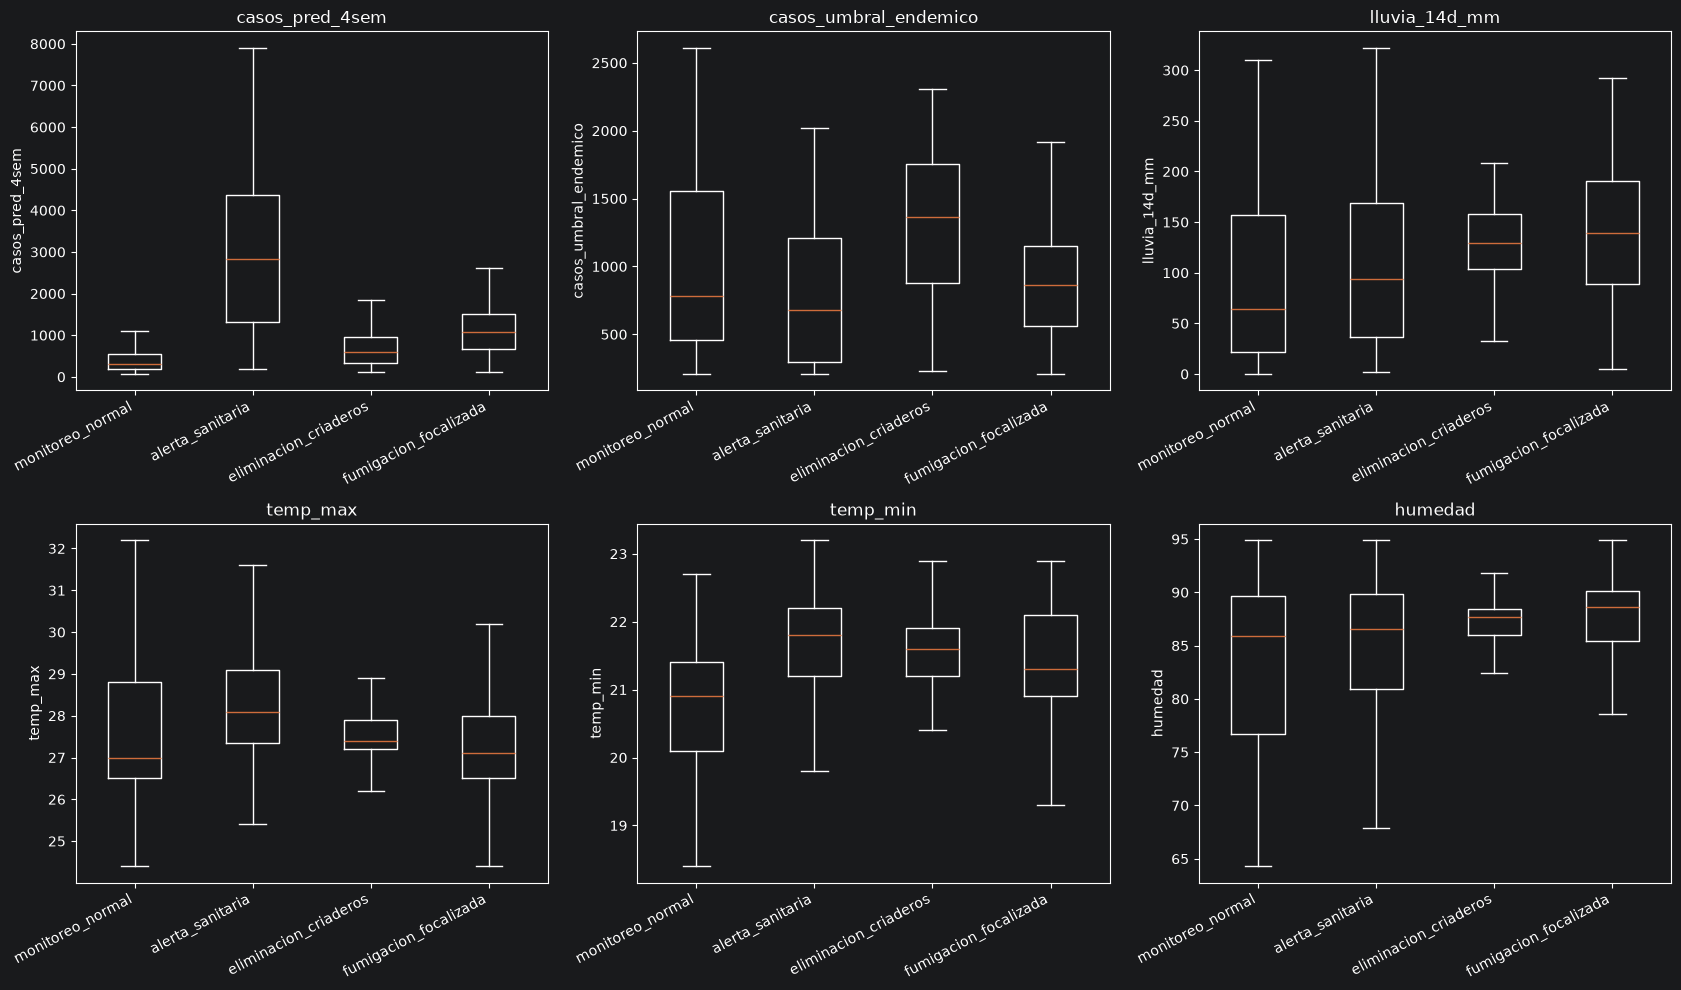

In [24]:
medianas_clase = datos.groupby("recomendacion")[variables_numericas + ["aegypti_detectado"]].median()
display(medianas_clase.round(2))

orden_clases = tabla_recomendaciones["Recomendación"].tolist()
fig, ejes = plt.subplots(2, 3, figsize=(17, 10))
for eje, variable in zip(ejes.flat, variables_numericas):
    series = [datos.loc[datos["recomendacion"] == clase, variable].dropna() for clase in orden_clases]
    eje.boxplot(series, positions=range(1, len(orden_clases) + 1), showfliers=False)
    eje.set_xticks(range(1, len(orden_clases) + 1))
    eje.set_xticklabels(orden_clases)
    eje.set_title(variable)
    eje.set_ylabel(variable)
    eje.tick_params(axis="x", labelrotation=28)
    for etiqueta in eje.get_xticklabels():
        etiqueta.set_ha("right")
plt.tight_layout()
plt.show()

## 25. Validación de reglas de etiquetado (orden de prioridad)

Se reconstruye la recomendación esperada usando exactamente las reglas del README del profesor:

1. Pronóstico de casos > 2 × umbral → `alerta_sanitaria`.
2. Pronóstico > umbral **y** Aedes detectado = 1 → `fumigacion_focalizada`.
3. Lluvia de 14 días > 80 mm **y** temperatura máxima > 27 °C → `eliminacion_criaderos`.
4. En otro caso → `monitoreo_normal`.

El profesor indica que hay ruido en una parte de las etiquetas. Las discrepancias se **identifican**, pero no se corrigen.

In [25]:
cond_alerta = datos["casos_pred_4sem"] > 2 * datos["casos_umbral_endemico"]
cond_fumigacion = (datos["casos_pred_4sem"] > datos["casos_umbral_endemico"]) & (datos["aegypti_detectado"] == 1)
cond_criaderos = (datos["lluvia_14d_mm"] > 80) & (datos["temp_max"] > 27)

datos["recomendacion_segun_regla"] = np.select(
    [cond_alerta, cond_fumigacion, cond_criaderos],
    ["alerta_sanitaria", "fumigacion_focalizada", "eliminacion_criaderos"],
    default="monitoreo_normal"
)
datos["etiqueta_difiere_regla"] = datos["recomendacion"] != datos["recomendacion_segun_regla"]

cantidad_discrepancias = int(datos["etiqueta_difiere_regla"].sum())
porcentaje_discrepancias = 100 * datos["etiqueta_difiere_regla"].mean()
print(f"Etiquetas que no coinciden con las reglas: {cantidad_discrepancias}")
print(f"Porcentaje observado de discrepancias: {porcentaje_discrepancias:.2f} %")
print("Cruce entre etiquetas reales y etiquetas calculadas por reglas:")
display(pd.crosstab(datos["recomendacion"], datos["recomendacion_segun_regla"]))
print("Ejemplos de discrepancias:")
display(datos.loc[datos["etiqueta_difiere_regla"],
    ["fecha_inicio_semana", "escenario", "casos_pred_4sem", "casos_umbral_endemico",
     "lluvia_14d_mm", "temp_max", "aegypti_detectado", "recomendacion", "recomendacion_segun_regla"]].head(10))

Etiquetas que no coinciden con las reglas: 44
Porcentaje observado de discrepancias: 2.14 %
Cruce entre etiquetas reales y etiquetas calculadas por reglas:


recomendacion_segun_regla,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
recomendacion,,,,
alerta_sanitaria,365,1,1,12
eliminacion_criaderos,2,305,0,14
fumigacion_focalizada,1,4,138,4
monitoreo_normal,2,2,1,1208


Ejemplos de discrepancias:


,fecha_inicio_semana,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,aegypti_detectado,recomendacion,recomendacion_segun_regla
93,2017-05-07,4,436,968,283.8,26.4,1,fumigacion_focalizada,monitoreo_normal
179,2017-09-03,5,474,1968,263.5,27.0,1,eliminacion_criaderos,monitoreo_normal
182,2017-09-10,3,416,1981,156.7,26.6,1,eliminacion_criaderos,monitoreo_normal
187,2017-09-17,3,384,1994,190.3,25.7,1,alerta_sanitaria,monitoreo_normal
260,2017-12-31,1,110,1348,55.0,25.1,0,eliminacion_criaderos,monitoreo_normal
301,2018-02-25,2,121,435,24.1,27.6,0,fumigacion_focalizada,monitoreo_normal
378,2018-06-10,4,381,1518,163.9,26.2,0,eliminacion_criaderos,monitoreo_normal
383,2018-06-17,4,275,1664,189.9,26.8,1,fumigacion_focalizada,monitoreo_normal
389,2018-06-24,5,277,1726,136.2,26.8,1,eliminacion_criaderos,monitoreo_normal
390,2018-07-01,1,372,1797,106.7,26.5,1,eliminacion_criaderos,monitoreo_normal


## 26. Análisis de etiquetas inconsistentes o con ruido

Se identifican las clases y años en que se concentran las discrepancias respecto a las reglas. Una discrepancia puede deberse al ruido descrito en el material y no prueba un error de carga.

,Registros,Discrepancias,Porcentaje (%)
recomendacion,,,
alerta_sanitaria,379,14,3.69
eliminacion_criaderos,321,16,4.98
fumigacion_focalizada,147,9,6.12
monitoreo_normal,1213,5,0.41


,Registros,Discrepancias,Porcentaje (%)
anio,,,
2017,260,4,1.54
2018,260,7,2.69
2019,260,4,1.54
2020,260,10,3.85
2021,260,9,3.46
2022,260,5,1.92
2023,260,2,0.77
2024,240,3,1.25


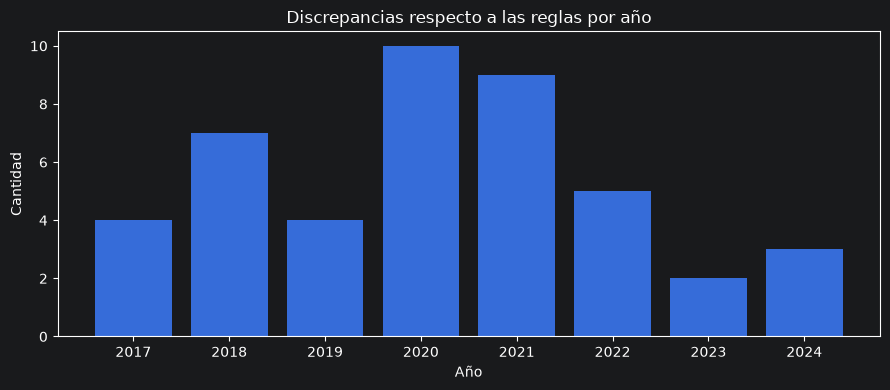

In [26]:
tabla_ruido_clases = datos.groupby("recomendacion")["etiqueta_difiere_regla"].agg(
    Registros="count", Discrepancias="sum", Proporcion="mean"
)
tabla_ruido_clases["Porcentaje (%)"] = (100 * tabla_ruido_clases.pop("Proporcion")).round(2)
display(tabla_ruido_clases)

tabla_ruido_anio = datos.groupby("anio")["etiqueta_difiere_regla"].agg(
    Registros="count", Discrepancias="sum", Proporcion="mean"
)
tabla_ruido_anio["Porcentaje (%)"] = (100 * tabla_ruido_anio.pop("Proporcion")).round(2)
display(tabla_ruido_anio)

plt.figure(figsize=(9, 4))
plt.bar(tabla_ruido_anio.index.astype(str), tabla_ruido_anio["Discrepancias"])
plt.title("Discrepancias respecto a las reglas por año")
plt.xlabel("Año")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

## 27. Escenarios repetidos por semana: similitudes y diferencias

Se mide la variación dentro de cada semana para observar qué campos se mantienen iguales y cuáles cambian entre los cinco escenarios. Esto es clave para evitar fugas entre conjuntos de datos.

Semanas donde una variable habitual cambia entre escenarios:


,Semanas con más de un valor
casos_umbral_endemico,0
lluvia_14d_mm,0
temp_max,0
temp_min,0
humedad,0


,pred_min,pred_max,detecciones_distintas,acciones_distintas,amplitud_pred
count,412.00,412.00,412.00,412.00,412.00
mean,790.44,1246.92,1.81,1.40,456.49
std,1030.44,1632.91,0.39,0.61,670.90
min,75.00,99.00,1.00,1.00,18.00
25%,188.75,300.00,2.00,1.00,101.75
50%,408.50,629.00,2.00,1.00,202.50
75%,870.00,1369.75,2.00,2.00,490.75
max,5394.00,10021.00,2.00,3.00,5789.00


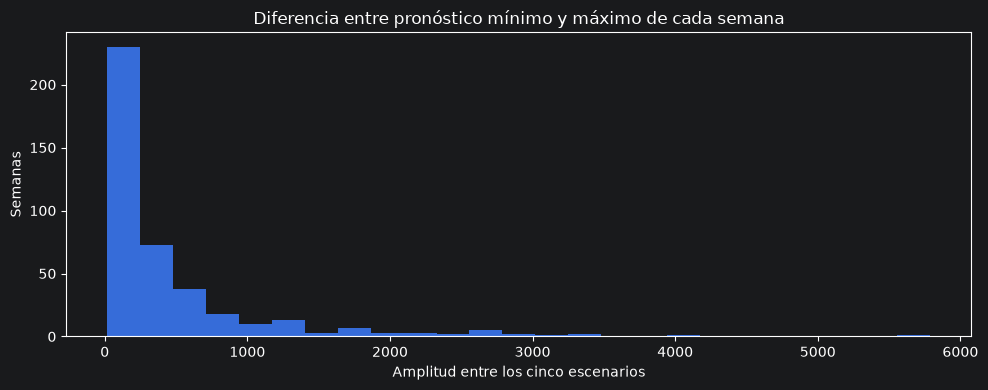

In [27]:
variables_clima = ["casos_umbral_endemico", "lluvia_14d_mm", "temp_max", "temp_min", "humedad"]
variacion_en_semana = datos.groupby("fecha_inicio_semana")[variables_clima].nunique()
semanas_clima_variable = (variacion_en_semana > 1).sum()
print("Semanas donde una variable habitual cambia entre escenarios:")
display(semanas_clima_variable.rename("Semanas con más de un valor").to_frame())

resumen_escenario = datos.groupby("fecha_inicio_semana").agg(
    pred_min=("casos_pred_4sem", "min"),
    pred_max=("casos_pred_4sem", "max"),
    detecciones_distintas=("aegypti_detectado", "nunique"),
    acciones_distintas=("recomendacion", "nunique")
)
resumen_escenario["amplitud_pred"] = resumen_escenario["pred_max"] - resumen_escenario["pred_min"]
display(resumen_escenario.describe().round(2))

plt.figure(figsize=(10, 4))
plt.hist(resumen_escenario["amplitud_pred"], bins=25)
plt.title("Diferencia entre pronóstico mínimo y máximo de cada semana")
plt.xlabel("Amplitud entre los cinco escenarios")
plt.ylabel("Semanas")
plt.tight_layout()
plt.show()

## 28. Distribución temporal de las recomendaciones

Se compara la frecuencia y proporción de cada recomendación por año. Los cinco escenarios de una semana no equivalen a cinco semanas diferentes.

Número de escenarios por recomendación y año:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
anio,,,,
2017,1,32,1,226
2018,1,49,2,208
2019,1,76,15,168
2020,53,30,32,145
2021,4,69,2,185
2022,4,30,49,177
2023,127,27,18,88
2024,188,8,28,16


Porcentaje de escenarios por recomendación y año:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
anio,,,,
2017,0.4,12.3,0.4,86.9
2018,0.4,18.8,0.8,80.0
2019,0.4,29.2,5.8,64.6
2020,20.4,11.5,12.3,55.8
2021,1.5,26.5,0.8,71.2
2022,1.5,11.5,18.8,68.1
2023,48.8,10.4,6.9,33.8
2024,78.3,3.3,11.7,6.7


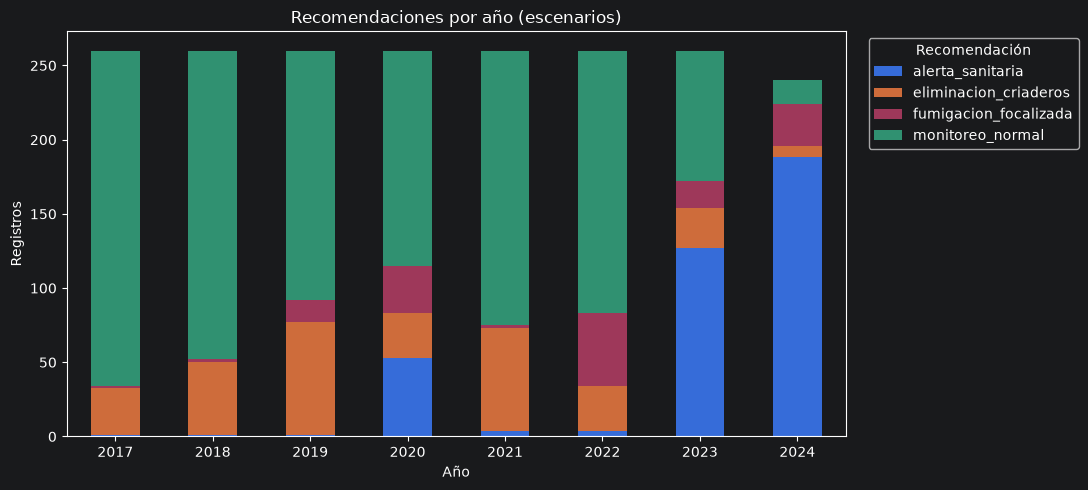

In [28]:
recomendaciones_anio = pd.crosstab(datos["anio"], datos["recomendacion"])
porcentajes_anio = pd.crosstab(datos["anio"], datos["recomendacion"], normalize="index").mul(100)
print("Número de escenarios por recomendación y año:")
display(recomendaciones_anio)
print("Porcentaje de escenarios por recomendación y año:")
display(porcentajes_anio.round(1))

recomendaciones_anio.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Recomendaciones por año (escenarios)")
plt.xlabel("Año")
plt.ylabel("Registros")
plt.xticks(rotation=0)
plt.legend(title="Recomendación", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 29. Relación entre semana epidemiológica y recomendación

Se explora si las recomendaciones se distribuyen de manera distinta a lo largo del año. Se agrupan las semanas epidemiológicas en cuatro tramos únicamente con fines descriptivos.

Cantidad por tramo epidemiológico:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
tramo_epidemiologico,,,,
Semanas 1–13,92,15,17,396
Semanas 14–26,77,118,60,265
Semanas 27–39,125,148,38,209
Semanas 40–53,85,40,32,343


Porcentajes dentro de cada tramo:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
tramo_epidemiologico,,,,
Semanas 1–13,17.7,2.9,3.3,76.2
Semanas 14–26,14.8,22.7,11.5,51.0
Semanas 27–39,24.0,28.5,7.3,40.2
Semanas 40–53,17.0,8.0,6.4,68.6


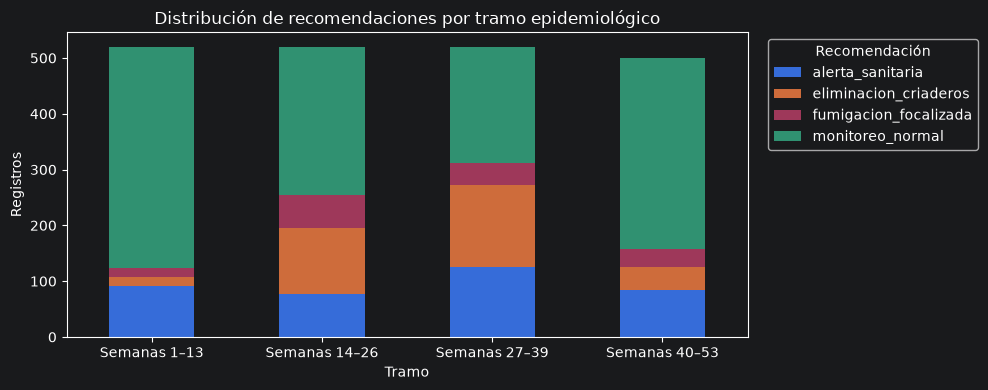

In [29]:
datos["tramo_epidemiologico"] = pd.cut(
    datos["semana_epi"], bins=[0, 13, 26, 39, 53],
    labels=["Semanas 1–13", "Semanas 14–26", "Semanas 27–39", "Semanas 40–53"],
    include_lowest=True
)
tramos = pd.crosstab(datos["tramo_epidemiologico"], datos["recomendacion"])
print("Cantidad por tramo epidemiológico:")
display(tramos)
print("Porcentajes dentro de cada tramo:")
display(pd.crosstab(datos["tramo_epidemiologico"], datos["recomendacion"], normalize="index").mul(100).round(1))
tramos.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Distribución de recomendaciones por tramo epidemiológico")
plt.xlabel("Tramo")
plt.ylabel("Registros")
plt.xticks(rotation=0)
plt.legend(title="Recomendación", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 30. Revisión de posibles fugas de información

La fecha de inicio de semana identifica el grupo de cinco escenarios. Separar aleatoriamente filas puede colocar escenarios de la misma semana en entrenamiento y prueba. Se documenta la estructura de grupos, **sin entrenar un modelo**.

In [30]:
grupos = datos.groupby("fecha_inicio_semana").agg(
    registros=("escenario", "size"),
    escenarios_distintos=("escenario", "nunique"),
    etiquetas_distintas=("recomendacion", "nunique")
)
print("Grupos semanales:", len(grupos))
print("Grupos con un número distinto de cinco filas:", int((grupos["registros"] != 5).sum()))
print("Grupos sin los cinco escenarios distintos:", int((grupos["escenarios_distintos"] != 5).sum()))
print("Semanas con más de una recomendación:", int((grupos["etiquetas_distintas"] > 1).sum()))
print("Clave recomendada de agrupación: fecha_inicio_semana")
display(grupos.head())

Grupos semanales: 412
Grupos con un número distinto de cinco filas: 0
Grupos sin los cinco escenarios distintos: 0
Semanas con más de una recomendación: 136
Clave recomendada de agrupación: fecha_inicio_semana


,registros,escenarios_distintos,etiquetas_distintas
fecha_inicio_semana,,,
2017-01-01,5,5,1
2017-01-08,5,5,1
2017-01-15,5,5,1
2017-01-22,5,5,1
2017-01-29,5,5,1


## 31. Comparación de clases entre entrenamiento y prueba (ejemplo temporal)

Se muestra **solo una división exploratoria**: 2017–2022 y 2023–2024. Esta separación conserva todos los escenarios de cada semana en el mismo período. Permite visualizar el cambio de distribución y advertir sobre resultados sesgados.

> No se crea ni se entrena una ANN en este apartado.

recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
periodo_evaluacion,,,,
Entrenamiento (2017–2022),64,286,101,1109
Prueba (2023–2024),315,35,46,104


Proporciones (%) por período:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
periodo_evaluacion,,,,
Entrenamiento (2017–2022),4.1,18.33,6.47,71.09
Prueba (2023–2024),63.0,7.00,9.20,20.80


Semanas compartidas entre entrenamiento y prueba: 0


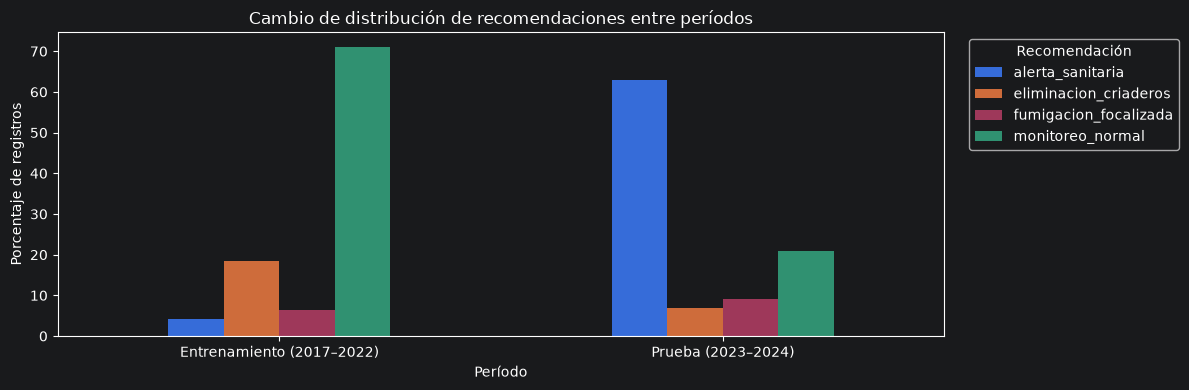

In [31]:
datos["periodo_evaluacion"] = np.where(
    datos["anio"] <= 2022, "Entrenamiento (2017–2022)", "Prueba (2023–2024)"
)
clases_por_periodo = pd.crosstab(datos["periodo_evaluacion"], datos["recomendacion"])
proporciones_periodo = pd.crosstab(
    datos["periodo_evaluacion"], datos["recomendacion"], normalize="index"
).mul(100)
display(clases_por_periodo)
print("Proporciones (%) por período:")
display(proporciones_periodo.round(2))

grupos_train = set(datos.loc[datos["anio"] <= 2022, "fecha_inicio_semana"])
grupos_test = set(datos.loc[datos["anio"] >= 2023, "fecha_inicio_semana"])
print("Semanas compartidas entre entrenamiento y prueba:", len(grupos_train & grupos_test))

proporciones_periodo.plot(kind="bar", figsize=(12, 4))
plt.title("Cambio de distribución de recomendaciones entre períodos")
plt.xlabel("Período")
plt.ylabel("Porcentaje de registros")
plt.xticks(rotation=0)
plt.legend(title="Recomendación", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 32. Comparación de recomendaciones entre escenarios

Se comprueba si los escenarios identificados como 1 a 5 concentran distintas recomendaciones. Esta tabla no implica que un escenario sea una clase o un paciente diferente.

Cantidades:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
escenario,,,,
1,72,66,34,240
2,74,60,36,242
3,81,64,20,247
4,79,64,29,240
5,73,67,28,244


Porcentajes dentro de cada escenario:


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
escenario,,,,
1,17.48,16.02,8.25,58.25
2,17.96,14.56,8.74,58.74
3,19.66,15.53,4.85,59.95
4,19.17,15.53,7.04,58.25
5,17.72,16.26,6.80,59.22


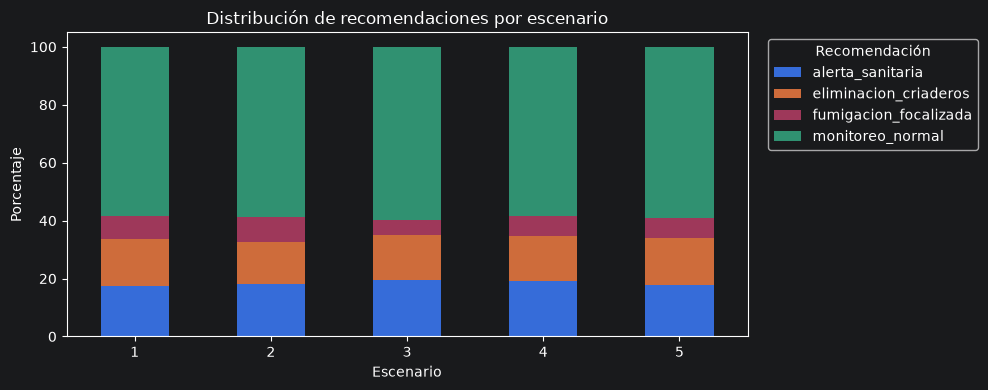

In [32]:
tabla_por_escenario = pd.crosstab(datos["escenario"], datos["recomendacion"])
porcentaje_por_escenario = pd.crosstab(datos["escenario"], datos["recomendacion"], normalize="index").mul(100)
print("Cantidades:")
display(tabla_por_escenario)
print("Porcentajes dentro de cada escenario:")
display(porcentaje_por_escenario.round(2))

porcentaje_por_escenario.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Distribución de recomendaciones por escenario")
plt.xlabel("Escenario")
plt.ylabel("Porcentaje")
plt.xticks(rotation=0)
plt.legend(title="Recomendación", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 33. Resumen automático del EDA

Se recopilan los indicadores principales de tamaño, calidad, etiquetas, escenarios, reglas y distribución temporal. **El resumen es descriptivo; no sustituye la interpretación ni las conclusiones del equipo.**

In [33]:
resumen_eda = pd.DataFrame([
    ("Total de registros", len(datos)),
    ("Columnas originales", columnas),
    ("Semanas diferentes", datos["fecha_inicio_semana"].nunique()),
    ("Escenarios distintos", datos["escenario"].nunique()),
    ("Semanas con los 5 escenarios", int(escenarios_completos)),
    ("Fecha inicial", datos["fecha_inicio_semana"].min().date().isoformat()),
    ("Fecha final", datos["fecha_inicio_semana"].max().date().isoformat()),
    ("Recomendaciones distintas", datos["recomendacion"].nunique()),
    ("Valores faltantes", int(faltantes.sum())),
    ("Filas duplicadas exactas", duplicados_exactos),
    ("Claves semana-escenario duplicadas", duplicados_clave),
    ("Controles de rango/consistencia observados", int(sum(controles.values()))),
    ("Relación clase mayoritaria / minoritaria", round(relacion_desbalance, 2)),
    ("Casos pronosticados mayores al umbral", int((datos["casos_pred_4sem"] > datos["casos_umbral_endemico"]).sum())),
    ("Casos pronosticados mayores a 2× umbral", int(cond_alerta.sum())),
    ("Lluvia > 80 mm y temperatura máx. > 27 °C", int(ambas_condiciones.sum())),
    ("Aedes detectado (simulado = 1)", int((datos["aegypti_detectado"] == 1).sum())),
    ("Etiquetas distintas de las reglas", cantidad_discrepancias),
    ("Etiquetas distintas de las reglas (%)", round(porcentaje_discrepancias, 2)),
    ("Semanas con recomendaciones variadas", int((grupos["etiquetas_distintas"] > 1).sum())),
    ("Semanas compartidas entre períodos temporales", len(grupos_train & grupos_test))
], columns=["Indicador", "Resultado"])

display(resumen_eda)
print("Distribución de recomendaciones:")
display(tabla_recomendaciones)
print("Diferencias entre período de entrenamiento y prueba (%):")
display(proporciones_periodo.round(2))
print("Discrepancias de etiquetas por clase:")
display(tabla_ruido_clases)
print("Variables con mayor número de valores atípicos (IQR):")
display(tabla_outliers.sort_values("Valores atípicos", ascending=False).head(6))

,Indicador,Resultado
0,Total de registros,2060
1,Columnas originales,12
2,Semanas diferentes,412
3,Escenarios distintos,5
4,Semanas con los 5 escenarios,412
5,Fecha inicial,2017-01-01
6,Fecha final,2024-11-24
7,Recomendaciones distintas,4
8,Valores faltantes,0
9,Filas duplicadas exactas,0


Distribución de recomendaciones:


,Recomendación,Cantidad,Porcentaje (%)
0,monitoreo_normal,1213,58.88
1,alerta_sanitaria,379,18.40
2,eliminacion_criaderos,321,15.58
3,fumigacion_focalizada,147,7.14


Diferencias entre período de entrenamiento y prueba (%):


recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
periodo_evaluacion,,,,
Entrenamiento (2017–2022),4.1,18.33,6.47,71.09
Prueba (2023–2024),63.0,7.00,9.20,20.80


Discrepancias de etiquetas por clase:


,Registros,Discrepancias,Porcentaje (%)
recomendacion,,,
alerta_sanitaria,379,14,3.69
eliminacion_criaderos,321,16,4.98
fumigacion_focalizada,147,9,6.12
monitoreo_normal,1213,5,0.41


Variables con mayor número de valores atípicos (IQR):


,Variable,Límite inferior,Límite superior,Valores atípicos,Porcentaje (%)
0,casos_pred_4sem,-1019.0000,2349.0000,236,11.46
2,lluvia_14d_mm,-164.7125,360.1875,50,2.43
5,humedad,66.3125,103.4125,50,2.43
3,temp_max,23.4500,31.8500,50,2.43
4,temp_min,18.5500,23.7500,10,0.49
1,casos_umbral_endemico,-954.6250,2830.3750,0,0.00



## 34. Conclusiones generales del EDA

El análisis exploratorio del dataset `vectoria_acciones.csv` permitió estudiar las variables utilizadas para recomendar acciones preventivas contra el dengue, evaluando su distribución, calidad, relaciones estadísticas y consistencia con las reglas de clasificación.

El objetivo fue identificar las características del conjunto de datos y los aspectos que deben considerarse antes del entrenamiento de la red neuronal artificial (ANN) del proyecto VectorIA.

### 34.1. Principales hallazgos

1. **Cantidad de registros:** se analizaron 2.060 registros y 12 columnas originales, correspondientes a 412 semanas comprendidas entre el 1 de enero de 2017 y el 24 de noviembre de 2024.

2. **Organización por escenarios:** cada semana contiene cinco escenarios diferentes, generando 412 grupos con cinco registros cada uno. Estos escenarios representan distintas condiciones de pronóstico y detección simulada del mosquito Aedes aegypti.

3. **Calidad de los datos:** no se encontraron valores faltantes, filas exactamente duplicadas ni combinaciones repetidas de semana y escenario. Esto representa una ventaja para la preparación de los datos.

4. **Distribución de recomendaciones:** se identificaron cuatro clases:
   - Monitoreo normal: 1.213 registros (58,88 %).
   - Alerta sanitaria: 379 registros (18,40 %).
   - Eliminación de criaderos: 321 registros (15,58 %).
   - Fumigación focalizada: 147 registros (7,14 %).

5. **Desbalance de clases:** se obtuvo una relación de 8,25:1 entre la clase mayoritaria y la minoritaria. Monitoreo normal representa más de la mitad del dataset, mientras que fumigación focalizada es la recomendación menos frecuente. Esta diferencia podría provocar que la ANN favorezca las clases con mayor cantidad de registros.

6. **Distribución de casos pronosticados:** la variable `casos_pred_4sem` presenta una distribución asimétrica hacia la derecha, con numerosos valores bajos y algunos pronósticos simulados considerablemente elevados, cercanos a 10.000 casos. Estos valores pueden representar escenarios epidémicos extremos.

7. **Comparación con el umbral endémico:** se identificaron 713 registros (34,61 %) donde los casos pronosticados superaron el umbral endémico y 370 registros (17,96 %) donde lo superaron por más del doble. Estas condiciones son importantes para determinar las recomendaciones de fumigación y alerta sanitaria.

8. **Condiciones climáticas:** se encontraron 505 registros (24,51 %) donde la lluvia acumulada de 14 días superó los 80 mm y la temperatura máxima fue mayor a 27 °C. Esta combinación corresponde a una de las condiciones utilizadas para recomendar la eliminación de criaderos, siempre que no se active una regla de mayor prioridad.

9. **Detección simulada de Aedes aegypti:** la variable `aegypti_detectado` presentó 857 registros positivos (41,60 %) y 1.203 negativos (58,40 %). Es importante considerar que esta variable fue simulada y no corresponde a predicciones reales de la CNN.

10. **Correlaciones entre variables:** se identificaron relaciones estadísticas importantes:
    - Temperatura máxima y humedad: r = -0,87.
    - Humedad y umbral endémico: r = 0,62.
    - Lluvia y humedad: r = 0,60.
    - Temperatura mínima y casos pronosticados: r = 0,45.
    - Lluvia y temperatura máxima: r = -0,47.

    Estas correlaciones muestran que algunas variables están considerablemente relacionadas entre sí. En particular, la fuerte relación negativa entre temperatura máxima y humedad podría representar redundancia de información que conviene evaluar durante el entrenamiento.

11. **Distribución de valores atípicos:** mediante el método del rango intercuartílico (IQR), se identificaron:
    - Casos pronosticados: 236 registros (11,46 %).
    - Lluvia acumulada: 50 registros (2,43 %).
    - Humedad: 50 registros (2,43 %).
    - Temperatura máxima: 50 registros (2,43 %).
    - Temperatura mínima: 10 registros (0,49 %).
    - Umbral endémico: 0 registros.

    Estos valores deben revisarse antes de considerarse errores, debido a que algunos pueden representar condiciones climáticas extremas o situaciones epidémicas reales y simuladas.

12. **Consistencia de las reglas:** se encontraron 44 registros (2,14 %) cuya recomendación no coincide con la obtenida al aplicar nuevamente las reglas de clasificación. Esta diferencia es compatible con el ruido introducido intencionalmente en las etiquetas del dataset, aunque debe verificarse la implementación de las reglas.

13. **Discrepancias por recomendación:** las diferencias con las reglas se distribuyeron de la siguiente manera:
    - Alerta sanitaria: 14 registros (3,69 % de la clase).
    - Eliminación de criaderos: 16 registros (4,98 %).
    - Fumigación focalizada: 9 registros (6,12 %).
    - Monitoreo normal: 5 registros (0,41 %).

    Fumigación focalizada presenta el mayor porcentaje de discrepancias respecto a su propia cantidad de registros.

14. **Variaciones entre escenarios:** se identificaron 136 semanas en las que los cinco escenarios generaron diferentes recomendaciones. Esto demuestra que los cambios simulados en las variables de entrada pueden modificar la acción preventiva recomendada.

15. **Diferencias temporales entre entrenamiento y prueba:** el análisis mostró un cambio considerable en la distribución de recomendaciones entre los períodos:
    - Entrenamiento (2017–2022): alerta sanitaria representa aproximadamente el 4,1 %.
    - Prueba (2023–2024): alerta sanitaria representa aproximadamente el 63,0 %.

    Esta diferencia se relaciona con la mayor actividad epidémica del período de prueba y representa un desafío importante para la capacidad de generalización de la ANN.

16. **Prevención de fugas de información:** no se identificaron semanas compartidas entre las particiones temporales propuestas. Sin embargo, los cinco escenarios de cada semana contienen información relacionada, por lo que no deben distribuirse aleatoriamente entre entrenamiento y prueba.

17. **Naturaleza de los datos:** el dataset combina información histórica real de casos y clima con variables simuladas, como el pronóstico de cuatro semanas y la detección de Aedes aegypti. Además, las recomendaciones fueron generadas mediante reglas con ruido intencional. Por esta razón, no deben interpretarse como decisiones sanitarias reales previamente verificadas.

### 34.2. Recomendaciones para el entrenamiento

- **Controlar el desbalance:** considerar el uso de `class_weight` para reducir el efecto de la diferencia entre las cuatro recomendaciones, especialmente en fumigación focalizada.

- **Evaluar individualmente cada clase:** utilizar Precision, Recall y F1-score por recomendación, además de métricas macro, para evitar que el buen rendimiento en monitoreo normal oculte errores en las clases minoritarias.

- **Mantener la agrupación por semana:** utilizar una separación temporal o técnicas como `GroupShuffleSplit` y `GroupKFold`, asegurando que los cinco escenarios de una misma semana permanezcan en el mismo conjunto.

- **Examinar las diferencias temporales:** prestar especial atención al cambio de distribución entre 2017–2022 y 2023–2024, debido a que puede reducir el rendimiento del modelo al enfrentarse a situaciones epidémicas diferentes.

- **Revisar las etiquetas inconsistentes:** analizar los 44 registros que no coinciden con las reglas originales, considerando que el dataset incorpora ruido intencional.

- **Conservar los valores extremos relevantes:** evitar eliminar automáticamente los valores atípicos, ya que algunos podrían representar escenarios importantes para la recomendación de acciones sanitarias.

- **Evaluar las correlaciones:** revisar la fuerte relación negativa entre temperatura máxima y humedad para determinar si existe redundancia que afecte el aprendizaje o la interpretación del modelo.

- **Estandarizar variables numéricas:** aplicar métodos de escalado utilizando únicamente los datos de entrenamiento, evitando incorporar información del conjunto de prueba.

- **Validar las reglas de prioridad:** comprobar que las recomendaciones respeten el orden establecido: alerta sanitaria, fumigación focalizada, eliminación de criaderos y monitoreo normal.

- **Analizar las recomendaciones minoritarias:** prestar especial atención a fumigación focalizada, debido a su baja representación y mayor porcentaje relativo de discrepancias con las reglas.

- **Comparar con las reglas originales:** utilizar el clasificador basado directamente en las reglas como referencia para evaluar qué aporta la ANN, considerando que las etiquetas se generaron mediante esas mismas reglas y contienen ruido intencional.

- **Integrar los modelos correctamente:** durante el funcionamiento final de VectorIA, reemplazar las entradas simuladas por el pronóstico real de la LSTM y la clasificación de la CNN, verificando que sus resultados tengan los formatos esperados por la ANN.

- **Evaluar la integración final:** comprobar el comportamiento de las recomendaciones cuando se utilizan predicciones reales de los modelos, debido a que estas podrían tener distribuciones y errores diferentes a los simulados durante la creación del dataset.

### 34.3. Conclusión final

El dataset `vectoria_acciones.csv` presenta una estructura adecuada para el desarrollo de una red neuronal artificial orientada a recomendar acciones preventivas contra el dengue. Contiene 2.060 registros organizados en 412 semanas y cinco escenarios por semana, sin valores faltantes ni registros duplicados.

El análisis identificó que uno de los principales desafíos es el desbalance entre las cuatro recomendaciones. Monitoreo normal representa el 58,88 % de los registros, mientras que fumigación focalizada únicamente alcanza el 7,14 %. Esta diferencia podría influir en el aprendizaje del modelo, por lo que será importante utilizar técnicas que permitan evaluar y mejorar el rendimiento de las clases menos frecuentes.

También se identificaron relaciones estadísticas relevantes entre las variables climáticas y epidemiológicas. Destaca la correlación negativa de -0,87 entre temperatura máxima y humedad, así como las relaciones positivas entre humedad, lluvia y umbral endémico. Estos resultados permitirán evaluar la utilidad de las variables durante el entrenamiento de la ANN.

Otro hallazgo importante fue la presencia de 44 registros cuyas etiquetas no coinciden con las reglas originales, equivalentes al 2,14 % del dataset. Esta situación es compatible con el ruido aleatorio introducido intencionalmente y deberá considerarse al evaluar el desempeño del clasificador.

El análisis temporal evidenció diferencias considerables entre los períodos de entrenamiento y prueba. La proporción de alertas sanitarias aumenta aproximadamente del 4,1 % durante 2017–2022 al 63,0 % durante 2023–2024. Esto constituye un desafío importante para la generalización de la ANN, ya que el modelo deberá responder a condiciones epidemiológicas diferentes a las predominantes durante el entrenamiento.

Asimismo, se comprobó la importancia de separar los datos por semana, debido a que los cinco escenarios asociados a una misma fecha comparten información relacionada. Una separación aleatoria por registro podría producir resultados artificialmente favorables durante la evaluación.

Es importante destacar que el dataset no contiene exclusivamente resultados observados. Algunas variables, como los casos pronosticados y la detección del mosquito, fueron simuladas, mientras que las recomendaciones se generaron mediante reglas previamente definidas. Por ello, la evaluación del modelo sobre estos datos no garantiza por sí sola que las recomendaciones sean efectivas en situaciones reales.

En conclusión, el dataset es apropiado para entrenar y evaluar la ANN del proyecto VectorIA, siempre que se consideren el desbalance de clases, las discrepancias de etiquetas, las diferencias temporales y la prevención de fugas de información.

Finalmente, será necesario comprobar el funcionamiento de la ANN al integrarla con las predicciones reales de la CNN y la LSTM, para determinar si mantiene un comportamiento adecuado cuando recibe resultados generados por los otros modelos del sistema.
